# Notebook 1: Deeltjesmodel

Computer simulaties zijn een belangrijk onderdeel bij natuurkundig onderzoek: wat we niet in het lab kunnen doen, of waar we niet goed aan kunnen meten, kunnen we alsnog bestuderen dankzij simulaties. In deze module leggen we de basis voor natuurkundige computer simulaties en maken we de eerste stappen in ons deeltjes model.

De basis van een goede computer simulatie ligt, net als bij het oplossen van een natuurkundig probleem in een gedegen systematische aanpak. Deze begint vaak met:
1. Het maken van een tekening van de situatie
2. Het noteren van de werkformules
3. Het aangeven van richtingen en noteren van variabelen. 

```{exercise}
Als startopdracht modelleren we twee fietsers. Doorloop de bovenstaande drie stappen. 
```



## Numerieke modellen
Om een simulatie te maken, splitsen we het volledige proces op in kleine stappen met een vaste (tijd)interval, zoals in onderstaande figuur. Elk stapje krijgt een nummer, van $0$ tot $N$. We gebruiken de letter $i$ om naar een specifieke stap te verwijzen.

De gegevens in stap $i$ worden gebruikt om de waarden in stap $i+1$ te berekenen, bijvoorbeeld:

$$x_{i+1} = x_i + v_i\cdot\Delta t$$

```{figure} ../figures/interval.jpg
:width: 50%

Het gehele proces wordt opgebroken in kleine stukken: tijdsdiscretisatie.
```
Wellicht heb je bovenstaande al eens gezien met het programma Coach. Anders dan bij Coach moeten we expliciet de waarden opslaan in een array. Omdat het steeds aanmaken van een nieuwe cel in een array veel rekentijd kost, is het handiger om eerst arrays te maken met waarde 0.

We nemen als voorbeeld twee fietsers, waarbij de fietser 1 een eenparige beweging uitvoert en fietser 2 een eenparig versnelde beweging:

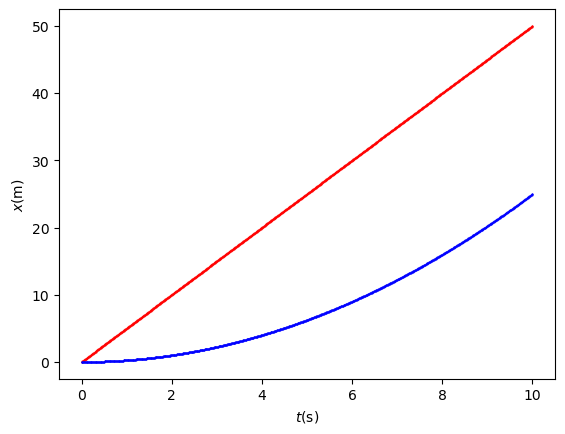

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Beginwaarden
dt = 0.01                  #s
t_e = 10                   #s
N = int(t_e/dt)+1
t = np.arange(0,t_e+dt,dt) #s

# fietser 1
x_1 = np.zeros(N)          #m     maakt array van lengte N met alleen maar waarde 0.
v_1 = 5                    #m/s

# fietser 2
x_2 = np.zeros(N)          #m     
v_2 = np.zeros(N)          #m/s     
a_2 = .5                   #m/s^2     

# Uitvoeren van de simulatie
for i in range(0,N-1):
    x_1[i+1] = x_1[i] + v_1*dt
    
    x_2[i+1] = x_2[i] + v_2[i]*dt
    v_2[i+1] = v_2[i] + a_2*dt

# Plotten van de gegevens.    
plt.figure()

plt.xlabel('$t$(s)')
plt.ylabel('$x$(m)')

plt.plot(t,x_1,'r.', markersize=1, label='fietser 1')
plt.plot(t,x_2,'b.', markersize=1, label='fietser 2')

plt.show()



Wat op zou kunnen vallen is dat de snelheid in een cel constant gehouden wordt ($x_i = v_i\cdot\Delta t$), terwijl de snelheid tijdens het tijdsinterval $\Delta t$ toeneemt. De oplossing is dus een benadering van de exacte oplossing, maar door deze methode (Euler explicit forward), moeten we wel voorzichtig zijn met de grootte van het tijdsinterval.

```{exercise}
Maak het tijdsinterval $dt$ groter en vergelijk de afgelegde weg in de tien seconde. Wat gebeurt er met de afgelegde weg als we $dt$ groter maken? Is dat logisch vanuit gezien de natuurkunde? En gezien de methode van discretisatie? Leg uit.
```

De afgelegde weg wordt groter naarmate de tijdsstap kleiner wordt. Dit is fysisch gezien logisch, omdat er relatief minder tijd is waarin de snelheid nog niet op een correct niveau ligt.

<!-- Jouw antwoord hier  -->

In [5]:
%reset -f  #clears memory as we don't need it further down 

ValueError: No closing quotation

## Naar een deeltjesmodel
In Q2 werken we aan een deeltjes model. Dat model bestaat uiteindelijk uit een stuk of 100 deeltjes die in een afgesloten volume bewegen. Om voor elk deeltje apart de eigenschappen te bepalen, wordt enorm veel code. Omdat de deeltjes dezelfde eigenschappen hebben (massa, radius, snelheid, positie) kunnen we gebruik maken van classes.

Een *class* is een blauwdruk voor het creëren van objecten (zoals deeltjes, atomen, planeten, auto's, studenten... noem maar op!). Het stelt je in staat om data (zoals positie, massa) en gedrag (zoals bewegen, botsen) te bundelen tot één overzichtelijk geheel. Precies wat we nodig hebben. Laten we de anatomie van een deeltje creëren.

In [6]:
# Definieer een class voor een deeltje. 
# Een class beschrijft alleen het type eigenschappen dat een ding heeft, bijvoorbeeld: in de beschrijving van de class zeg je:
# - een deeltje heeft een positie.
# - een deeltje heeft een functie die, wanneer aangeroepen, de positie van dat deeltje bijwerkt.
# Merk op dat de class zelf geen deeltje is! 
# Een object dat tot een bepaalde class behoort, wordt een instant van die class genoemd. 
# Je kunt meerdere instants van een class hebben.

class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                         # massa van het deeltje
        self.v = np.array(v, dtype=float)  # snelheids vector
        self.r = np.array(r, dtype=float)  # positie vector
        self.R = np.array(R, dtype=float)  # radius van het deeltje

    def update_position(self,dt):
        """Werk de positie van het deeltje bij op basis van zijn snelheid en tijdstap dt."""
        self.r += self.v * dt

print(ParticleClass)

<class '__main__.ParticleClass'>


We hebben alleen de class aangemaakt, maar nog niet een object zelf. Dat moeten we dus nog doen. 

We hebben ook met onze class de mogelijkheid gemaakt om een nieuwe positie uit te rekenen: de volgende positie is de huidige positie + de snelheid maal de tijdstap, ofwel: 

$$ x_{n+1}=x_n + v\cdot\Delta t $$

Laten we nu een ook echt een deeltje creëren en kijken wat we ermee kunnen doen.

In [7]:
# een enkel deeltje:
this_particle = ParticleClass(m=1.0, v=[5.0, 0], r=[0.0, 0.0], R=1.0)
print(this_particle)

In [8]:
%whos

Variable        Type             Data/Info
------------------------------------------
N               int              1001
ParticleClass   type             <class '__main__.ParticleClass'>
a_2             float            0.5
dt              float            0.01
i               int              999
np              module           <module 'numpy' from '/us<...>kages/numpy/__init__.py'>
plt             module           <module 'matplotlib.pyplo<...>es/matplotlib/pyplot.py'>
t               ndarray          1001: 1001 elems, type `float64`, 8008 bytes
t_e             int              10
this_particle   ParticleClass    <__main__.ParticleClass object at 0x7a3e4fa92f90>
v_1             int              5
v_2             ndarray          1001: 1001 elems, type `float64`, 8008 bytes
x_1             ndarray          1001: 1001 elems, type `float64`, 8008 bytes
x_2             ndarray          1001: 1001 elems, type `float64`, 8008 bytes


Nu we een object hebben, laten we eens kijken of we de eigenschappen van het object kunnen opvragen:

In [11]:
print("Massa van het deeltje " + str(this_particle.m) + " kg")
print("Huidige positie is " + str(this_particle.r))

# oproepen van de functie 'update_position' met dt = 1.0 seconde
this_particle.update_position(1.0)
print("Nieuwe positie " + str(this_particle.r))

Massa van het deeltje 1.0 kg
Huidige positie is [10.  0.]
Nieuwe positie [15.  0.]


Let op! Run je bovenstaande cell opnieuw, dan zal de positie ook steeds veranderen!

Laten we nog een deeltje maken om te laten zien dat het aanroepen van update op het ene deeltje geen invloed heeft op het andere deeltje: het zijn onafhankelijke objecten!

In [12]:
that_particle = ParticleClass(m=1.0, v=[2.0, 0], r=[5.0, 0.0],R=1.0)

In [13]:
print("Huidige positie van this_particle " + str(this_particle.r))
print("Huidige position van that_particle " + str(that_particle.r))

# oproepen van de functie 'update_position' met dt = 2.0 seconde
that_particle.update_position(2.0)
print("Nieuwe positie van this_particle " + str(this_particle.r))
print("Nieuwe positie van that_particle " + str(that_particle.r))

Huidige positie van this_particle [15.  0.]
Huidige position van that_particle [5. 0.]
Nieuwe positie van this_particle [15.  0.]
Nieuwe positie van that_particle [9. 0.]


We kunnen ook een array van objecten maken.
Dat zou eenvoudig moeten kunnen als het gaat om dezelfde deeltjes (zelfde massa, snelheid, maar andere startpositie). 

In [14]:
particle_array = []

for start_x in range(4):
    particle_array.append(ParticleClass(m=1.0, v=[2.0, 0], r=[start_x, 0.0],R=1.0))

print("Hoe het array eruit ziet volgens python: " + str(particle_array))
print("Hoe een element van het array eruit ziet volgens python: " + str(particle_array[0]))
print("Hoe een eigenschap (in dit geval: 'r') van het element van het array eruit ziet volgens python: " + str(particle_array[0].r))

Hoe het array eruit ziet volgens python: [<__main__.ParticleClass object at 0x7a3e4ec23250>, <__main__.ParticleClass object at 0x7a3e4f6baea0>, <__main__.ParticleClass object at 0x7a3e4eac4050>, <__main__.ParticleClass object at 0x7a3e4ecd8710>]
Hoe een element van het array eruit ziet volgens python: <__main__.ParticleClass object at 0x7a3e4ec23250>
Hoe een eigenschap (in dit geval: 'r') van het element van het array eruit ziet volgens python: [0. 0.]


```{exercise} Voorspel
:label: ex-intro-1

Gegeven bovenstaande particles die je hebt aangemaakt, hoe zien de posities er dan uit van die deeltjes?
Voorspel en controleer vervolgens met onderstaande code.
```

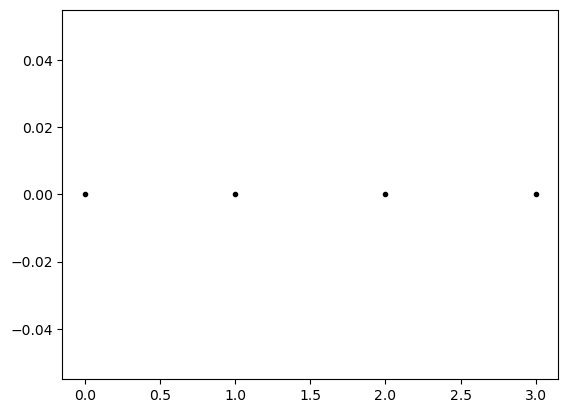

In [15]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure()
for particle in particle_array:
    plt.plot(particle.r[0],particle.r[1],'k.')
plt.show()


Wat eerder op moet zijn gevallen, en wat hierboven ook weer duidelijk wordt is dat de positie een 2D vector is.
We kunnen dus onafhankelijk in de $x$ en $y$ richting bewegen!

Door gebruik te maken van een array waarin alle deeltjes zijn opgeslagen, kun je voor elk deeltje dezelfde bewerking uitvoeren, bijvoorbeeld allemaal een stukje updaten in de tijd!
Hierbij kan je mooi gebruik maken van hoe Python loops maakt: als je één voor één de verschillende elementen van array af wilt gaan en daar dezelfde bewerking op doen, gaat dat zo:

In [ ]:
for particle, particle_object in enumerate(particle_array):
    print("Deeltje " + str(particle) + ", huidige positie: " + str(particle_object.r))
    print("oproepen van de functie 'update_position' met dt = 1.0 second ")
    particle_object.update_position(1.0)
    print("Volgende positie " + str(particle_object.r))
    if particle < len(particle_array) - 1:
        print("Naar het volgende deeltje \n")
    

Let op! In bovenstaande code maken we handig gebruik van twee programmeerconcepten.
`enumerate` hangt een nummer (counter) aan elk item in de array. Zo kun je bijhouden met welk deeltje je bezig bent. 

Omdat onze code steeds aan het eind aangeeft dat het naar het volgende deeltje gaat, moet die code alleen stoppen bij het laatste deeltje.
We hebben hier gebruik gemaakt van het `if` statement.
Deze manier van werken is misschien niet heel efficient - het kost rekentijd - maar kan enorm helpen bij debuggen van code: je ziet snel welke tekst wel en welke tekst niet geprint wordt.


```{exercise}
:label: intro-ex-2
Maak 10 deeltjes, elk startend op (een andere positie op) de x-as. Elk deeltje heeft een eigen random snelheid tussen de -5 en +5.
Update de positie en plot de positie van elk deeltje. 

En als je wilt gaan voor een uitdaging: 
- plot in dezelfde figuur de begin en eindpositie van elk deeltje
- maak gebruik van een kleine verticale snelheid om het verschil te kunnen zien.
- hoe zou je elk deeltje een andere kleur kunnen geven in de plot zodat ze ook echt traceerbaar zijn?
```

In [ ]:
# your code here

Onze simulaties worden snel “zwaar”. Er moeten veel berekeningen gedaan worden en dat kost nu eenmaal tijd. Nu is het wel zo dat sommige berekeningen meer tijd kosten dan anderen. Om te kijken of een stukje code geoptimaliseerd kan worden, moeten we een timer maken. Dat kan met onderstaande code:

In [ ]:
import time
import numpy as np

start = time.time()

array = np.array([])
N = int(1e5)

for i in range(N):
    array = np.append(array,np.random.rand(1))

eind = time.time()
lengte = eind - start

print("Dit kostte ", lengte, "seconde!")

Idealiter draaien we de bovenstaande code een aantal keer zodat we een goede schatting hebben van de rekentijd.

```{exercise} Timen
:label: ex-intro-3

Bovenstaande code kan natuurlijk veel sneller, in de functie random.rand() kun je het aantal elementen (N) mee geven. D
Voeg in bovenstaande code-cell de alternatieve methode voor het maken van de array toe en bereken de runtime.
Hoeveel keer korter is de runtime?
```

```{tip}
Met de MyST extentie in jupyterlab kun je gebruik maken van [eval](https://mystmd.org/guide/notebooks-with-markdown#myst-inline-expressions). Hieronder kun je de naam van je variabele invoeren die je hierboven heb gespecificeerd om uit te drukken hoeveel korter de runtime is.
```

```{solution} ex-intro-3
De runtime is {eval}`<naam variabele>` korter.
```

## Aan de slag met deeltjes
Zoom je heel ver in, dan zie je deeltjes rond vliegen.
Elk met een eigen massa, een eigen snelheid en richting.
De deeltjes botsen onderling, wisselen energie uit.
We zouden op basis van een botsingsmodel van deeltjes iets moeten kunnen leren over thermodynamica.
In de thermodynamica gaat het dan om heel veel deeltjes. Maar laten we beginnen met twee botsende 'deeltjes'.

```{exercise}
:label: ex-deeltjes-1
Bekijk onderstaande video.
```

```{iframe} https://www.youtube.com/embed/HEfHFsfGXjs?si=g37KWYOi0LqmuAkD
```

Je raadt het misschien al... deze simulatie gaan we na bouwen!
Daarbij maken we gebruik van Python classes uit het vorige hoofdstuk en de basics van simulaties geleerd in Q1.
Zorg er dus voor dat je weet hoe dit werkt!
We maken ook gebruik van plotten, en daarbovenop een animatie.
Hoe de animatie precies werkt en hoe je die zelf maakt hoef je niet te weten.
Je zou wel in staat moeten zijn de code te lezen.

In de onderstaande cell maken we de ParticleClass aan, en geven we enkele parameters van onze simulatie op.

In [ ]:
# Importeren van libraries
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Maken van de class
class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                         
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R

    def update_position(self):
        self.r += self.v * dt

# Simulation parameters
dt = 0.1                                                            # tijd stap
num_steps = 500                                                     # aantal te nemen stappen
particle = ParticleClass(m=1.0, v=[5.0, 0], r=[0.0, 0.0], R=1.0)    # het maken van ons deeltje

```{note} dt
In bovenstaande `update_position` functie hebben we de tijdstap niet als inputvariabele meegegeven, waarbij we dat in de eerdere module wel hebben gedaan.
In deze module gaan we er vanuit dat de tijdstap altijd hetzelfde is voor alle deeltjes in de simulatie.
Daarom definiëren we de tijdstap als een globale variabele in de simulatie.
```

We hebben nu een deeltje met massa, een snelheid, een begin positie en een straal.
We hebben ook al de stapgrootte bepaald!

We willen de beweging van dat deeltje straks bestuderen en moeten dus een plot maken:

In [ ]:
# Creeer een figuur en de assen
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Animatie")
ax.set_xlabel("x")
ax.set_ylabel("y")

# Toon het deeltje als een rode stip
dot, = ax.plot([], [], 'ro', markersize=10); # semicolon to suppress output

Bij het aanmaken van ons deeltje hebben we het deeltje een beginpositie en snelheid mee gegeven.
Als we dan per tijdstap de positie bepalen en deze laten plotten en die plots achter elkaar plakken, dan krijgen we een animatie van het deeltje.
Met FuncAnimation wordt die animatie voor ons gedaan.

In [ ]:
# Initialisieren van de functie voor de animatie
def init():
    dot.set_data([], [])
    return dot,

# Updaten van de functie voor elk frame
def update(frame):
    particle.update_position()
    dot.set_data([particle.r[0]], [particle.r[1]])
    return dot,

# Creeer de animatie
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# Omdat we werken met Jup. Notebooks (en niet een .py file)
from IPython.display import HTML
HTML(ani.to_jshtml())


`Frames` in FuncAnimation verwijst naar het totaal aantal frames dat gebruikt wordt.
`Interval` naar de snelheid van de animatie, nl. 50 milliseconden ofwel 20 frames per seconde.

Merk op dat als we de laatste cel opnieuw runnen, het deeltje zich niet in de oorsprong bevindt.
Dat is een 'eigenaardigheid' van Jupyter Notebooks.
Het is nu beter om alle code in één cel te plaatsen (hieronder gedaan voor je), zodat we ervoor zorgen dat het deeltje altijd in de oorsprong begint.


In [ ]:
# Simulation parameters
dt = 0.1         # time step
num_steps = 500  # number of time steps
particle = ParticleClass(m=1.0, v=[5.0, 0], r=[0.0, 0.0],R=1.0)  

# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")

# Create the particle as a red dot
dot, = ax.plot([], [], 'ro', markersize=10)

# Initialization function for animation
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    particle.update_position()
    dot.set_data([particle.r[0]], [particle.r[1]])
    return dot,

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())


Een van de dingen die je kunt opmerken, is dat het deeltje niet in zijn doos blijft.

```{exercise} Doorlopende doos
:label: ex-deeltjesmodel-2
Pas de onderstaande code aan zodat de doos een aaneengesloten doos is; als hij links eruit vliegt, komt hij er rechts in (en vice versa).

Controleer je eigen antwoord door de functie hierboven even te vervangen door deze functie, bekijk het resultaat.
```

In [ ]:
# doorlopende doos
def update(frame):
    particle.update_position()
    dot.set_data([particle.r[0]], [particle.r[1]])
# your code here
    return dot,         

```{exercise} Harde wanden
:label: ex-deeltjesmodel-3
Een tweede optie is dat we een doos hebben met harde wanden. Op het moment dat het deeltje de wand raakt, wordt deze gereflecteerd. Schrijf hieronder de code zodat het deeltje in zijn doos blijft, waarbij de doos harde wanden heeft.

Test wederom je code door de vernieuwde functie hierboven te plakken.
```

In [ ]:
# harde wanden
def update(frame):
    particle.update_position()
    dot.set_data([particle.r[0]], [particle.r[1]])
# your code here
    return dot,

```{exercise}
:label: ex-deeltjesmodel-4

Verander nu de code zodanig dat de beginsnelheid gegeven wordt door $\vec{v}=5\hat{x} + 3\hat{y}$ en het deeltje botst tegen alle muren.
```

In [ ]:
# Simulation parameters
dt = 0.1         # time step
num_steps = 500  # number of time steps

# your code here

# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")

# Create the particle as a red dot
dot, = ax.plot([], [], 'ro', markersize=10);

# Initialization function for animation
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    particle.update_position()
    dot.set_data([particle.r[0]], [particle.r[1]])
    # your code here
    return dot,

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())

Laten we teruggaan naar ons deeltje. Er is een functie om de positie bij te werken, hoewel de snelheid hetzelfde lijkt te blijven... kunnen we de snelheid veranderen door (bijvoorbeeld) de versnelling door de zwaartekracht?

````{exercise}
:label: ex-deeltjesmodel-5

Hieronder is de ParticleClass aangepast zodat er gebruik gemaakt kan worden van een versnelling.
Maak de simulatie van het deeltje zodat het zich beweegt in een zwaartekrachtsveld met $a = -9.81\hat{y}$.

```{tip}
De tweede solution kun je van hierboven kopieren natuurlijk!
```
````

```python
# Maken van de class met versnelling
class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                         # mass of the particle
        self.v = np.array(v, dtype=float)  # velocity vector
        self.r = np.array(r, dtype=float)  # position vector
        self.R = R                         # radius of the particle

    def update_position(self):
        self.r += self.v * dt
    
    def update_velocity(self, a):
        self.v += a*dt
```


In [ ]:

# Simulation parameters
dt = 0.1         # time step
num_steps = 500  # number of time steps
particle = ParticleClass(m=1.0, v=[5.0, 0], r=[0.0, 0.0],R=1.0)  
# your code here
# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")

# Create the particle as a red dot
dot, = ax.plot([], [], 'ro', markersize=10);

# Initialization function for animation
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    particle.update_velocity(a)
    particle.update_position()
    
    dot.set_data([particle.r[0]], [particle.r[1]])
    # your code here
    return dot,

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())


```{exercise}
:label: ex-deeltjesmodel-6

Wat valt je op aan het behoud van energie?!
Herinner wat we in Q1 hebben gedaan bij de basics van een numerieke simulatie...
```

```{solution} ex-deeltjesmodel-6
Jouw antwoord hier...
```

Een optie om de simulatie te verbeteren is de tijdstap $\Delta t$ kleiner te maken, maar dan hebben we ook meer geduld meer nodig - het aantal berekeningen schaalt met $\frac{1}{\Delta t}$. Een tweede optie is een meer directe oplossing: We weten dat $a = \mathrm{const.}$ en daarom weten we ook de bewegingsvergelijking van het deeltje!

We willen ook graag weten waar het deeltje is geweest, dat is in onderstaande code toegevoegd.

In [ ]:
# Maken van de class met versnelling
class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                  
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R  

    def update_position(self):
        self.r += self.v * dt + 1/2 * a * dt**2  
    
    def update_velocity(self, a):
        """Update the particle's velocity."""
        self.v += a*dt

# Simulation parameters
dt = 0.1         
num_steps = 500  
particle = ParticleClass(m=1.0, v=[0, 0], r=[0.0, 0.0],R=1.0)  
a = np.array([0.0, -5.0])  

track_x = []
track_y = []

# creeeren van de plot en de assen
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")
track_line, = ax.plot([], [], 'r--', linewidth=1)  

# creeeren van ons rode deeltje
dot, = ax.plot([], [], 'ro', markersize=10);

# initializeren van onze functie voor de animatie
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    particle.update_position()
    particle.update_velocity(a)

    track_x.append(particle.r[0])
    track_y.append(particle.r[1])
    track_line.set_data(track_x, track_y)
    
    dot.set_data([particle.r[0]], [particle.r[1]])
    if particle.r[0]**2>100: # Check if particle is outside the bounds, np.abs could be used but is slower
        particle.v[0] = -particle.v[0]
    if particle.r[1]**2>100: # Check if particle is outside the bounds, np.abs could be used but is slower
        particle.v[1] = -particle.v[1]
    return dot, track_line

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())

We hebben steeds slechts gewerkt met een enkel deeltje. Maar om de simulatie uit het filmpje te maken, hebben we twee deeltjes nodig.

```{exercise}
:label: ex-deeltjesmodel-7

Maak de code hieronder voor twee deeltjes die bewegen in een afgesloten doos. Beide deeltjes ondervinden een zwaartekracht. Beide deeltjes starten op hetzelfde punt, zonder beginsnelheid in de verticale richting. Echter, een van de twee deeltjes heeft een initiële horizontale snelheid.
```

In [ ]:
# Simulation parameters
dt = 0.1         # time step
num_steps = 500  # number of time steps
particleA = ParticleClass(m=1.0, v=[0, 0], r=[0.0, 0.0],R=1.0)  
# your code here

track_x = []
track_y = []

# Create the figure and axis
fig, ax = plt.subplots()
ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")
track_line, = ax.plot([], [], 'r--', linewidth=1)  

# Create the particle as a red dot
dotA, = ax.plot([], [], 'ro', markersize=10)
dotB, = ax.plot([], [], 'bo', markersize=10)

# Initialization function for animation
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    particleA.update_position()
    particleA.update_velocity(a)

# your code here

    track_x.append(particleA.r[0])
    track_y.append(particleA.r[1])
    track_line.set_data(track_x, track_y)
    
    dotA.set_data([particleA.r[0]], [particleA.r[1]])
    dotB.set_data([particleB.r[0]], [particleB.r[1]])

    # Check if either particle is outside the bounds, np.abs could be used but is slower
    if particleA.r[0]**2>100: 
        particleA.v[0] = -particleA.v[0]
    if particleA.r[1]**2>100: 
        particleA.v[1] = -particleA.v[1]

    if particleB.r[0]**2>100:
        particleB.v[0] = -particleB.v[0]
    if particleB.r[1]**2>100: 
        particleB.v[1] = -particleB.v[1]

    return dot, track_line

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())

Nu je een beetje weet hoe een numeriek model werkt, hoe je boundaries kunt opgeven, deeltjes kunt laten versnellen etc, gaan we de deeltjes echt laten interacteren. Hierboven bewogen ze immers nog door elkaar heen...

## Botsingen in 1D
```{exercise}
:label: ex-deeltjes_10

1. Gegeven twee particles elk met straal $R$ en posities $r_1$ en $r_2$. Wat is de (wiskundige) voorwaarde voor een botsing?

2. Kijk naar de onderstaande code en schrijf de voorwaarde voor een botsing op (m.a.w. maak de functie `collide_detection(self, other)` werkend).

3. Vul onderstaande code aan waarbij de twee deeltjes van richting veranderen wanneer ze botsen.

4. Automatiseer en maak de code eleganter waar mogelijk. Kijk daarvoor ook terug naar het aanmaken van een particlearray.
```

```{solution} ex-deeltjes_10
Jouw antwoord.
```

In [ ]:
# Define a class for a particle

# Maken van de class met botsing
class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                  
        self.v = np.array(v, dtype=float)  
        self.r = np.array(r, dtype=float)  
        self.R = R 

    def update_position(self):
        self.r += self.v * dt  

    def collide_detection(self, other):
        # your code here
        return  dx**2+dy**2 < rr**2 

In [ ]:
# Simulation parameters
dt = 0.1         # time step
num_steps = 200  # number of time steps

particleA = ParticleClass(m=1.0, v=[2.5, 0], r=[-2.0, 0.0],R=0.45)  
particleB = ParticleClass(m=1.0, v=[-1, 0], r=[0.0, 0.0],R=0.45)  

track_x = []
track_y = []


# Creer de plot

fig, ax = plt.subplots()

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")
track_line, = ax.plot([], [], 'r--', linewidth=1)  

# Toon het deeltje als een rode stip
dot, = ax.plot([], [], 'ro', markersize=10); # semicolon to suppress output
dotA, = ax.plot([], [], 'ro', markersize=10)
dotB, = ax.plot([], [], 'bo', markersize=10)

# Initaliseren voor de animatie
def init():
    dot.set_data([], [])
    return dot,

# Updaten van de functie per frame
def update(frame):
    particleA.update_position()
    particleB.update_position()

    track_x.append(particleA.r[0])
    track_y.append(particleA.r[1])
    track_line.set_data(track_x, track_y)
    
    dotA.set_data([particleA.r[0]], [particleA.r[1]])
    dotB.set_data([particleB.r[0]], [particleB.r[1]])

    # botsing tussen de deeltjes onderling
    if particleA.collide_detection(particleB):
        # your code here


    # botsing met de wand
    if particleA.r[0]**2>100: 
        particleA.v[0] = -particleA.v[0]
    if particleA.r[1]**2>100: 
        particleA.v[1] = -particleA.v[1]

    dot.set_data([particleB.r[0]], [particleB.r[1]])
    if particleB.r[0]**2>100: 
        particleB.v[0] = -particleB.v[0]
    if particleB.r[1]**2>100: 
        particleB.v[1] = -particleB.v[1]

    return dot, track_line

# Creeer animatie
ani = FuncAnimation(fig, update, frames=range(num_steps), init_func=init, blit=True, interval=50)

# Voor Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())

Terug naar ons vraagstuk... 
we willen een simulatie waarbij een deeltje met een massa $m_1$ en snelheid $v_1$ op een andere stilstaand deeltje met massa $m_2$ botst.
Deeltje twee beweegt naar een muur, botst tegen de muur en beweegt richting deeltje 1 en botst tegen dit deeltje.
Hoe vaak vindt deze botsing plaats als functie van de massa verhouding $\frac{m_1}{m_2}$?

Daarvoor moeten we even terug naar het botsingsmodel zoals geleerd in [*Klassieke Mechanica*.](https://freekpols.github.io/Mechanica/content/classic/collisions)
Bij elastische botsingen is zowel het impulsmoment als de kinetische energie behouden. 

$$
    \sum_i \vec{p}_i^{before} = \sum_i \vec{p}_i^{after}
$$

$$ 
    E_{kin, before} = E_{kin, after} 
$$

Voor een botsing met twee deeltjes levert dit een analytische oplossing:

$$
\begin{align}
\mathbf{v}'_1 &= \mathbf{v}_1-\frac{2 m_2}{m_1+m_2} \ \frac{\langle \mathbf{v}_1-\mathbf{v}_2,\,\mathbf{x}_1-\mathbf{x}_2\rangle}{\|\mathbf{x}_1-\mathbf{x}_2\|^2} \ (\mathbf{x}_1-\mathbf{x}_2),
\\
\mathbf{v}'_2 &= \mathbf{v}_2-\frac{2 m_1}{m_1+m_2} \ \frac{\langle \mathbf{v}_2-\mathbf{v}_1,\,\mathbf{x}_2-\mathbf{x}_1\rangle}{\|\mathbf{x}_2-\mathbf{x}_1\|^2} \ (\mathbf{x}_2-\mathbf{x}_1)
\end{align}
$$

we vragen je natuurlijk niet om deze vergelijking zelf te schrijven in Python, maar die vergelijking operationaliseren we hieronder wel.

```{exercise} Lezen van code
:label: ex-deeltjes-10

Lees onderstaande code, en probeer wijs te worden wat elk deel van de code doet. 
In het volgende hoofdstuk wordt de code net iets anders gestructureerd en uitgebreider uitgelegd.
```

```{exercise} Toevoegen van een counter
:label: ex-deeltjes-11

Als je de code runt, zie je dat het botsingsmodel goed lijkt te werken.
Er is zelfs een counter toegevoegd die het aantal botsingen dat plaats vindt zou moeten weergeven.
Maar in de code wordt de counter nog niet geupdate.

Voeg op de juiste plaats(en) een update van de counter toe (per botsing moet de counter 1 omhoog gezet worden).
```

```{exercise} Controleer
:label: ex-deeltjes-12

Controleer de uitspraak in de video dat $\pi$ in eens opduikt bij de massaverhouding. 

Wat is de beperkende factor in ons script om het aantal botsingen als functie van de massaverhouding te onderzokeen?
```

```{solution} ex-deeltjes-12
Jouw antwoord
```


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

class ParticleClass:
    def __init__(self, m, v, r, R):
        self.m = m                  # mass of the particle
        self.v = np.array(v, dtype=float)  # velocity vector
        self.r = np.array(r, dtype=float)  # position vector
        self.R = R                         # radius of the particle

    def update_position(self):
        self.r += self.v * dt 

    def collide_detection(self, other):
        return np.linalg.norm(self.r - other.r) <= (self.R + other.R)

# Simulation parameters
dt = 0.1         # time step
num_steps = 530  # number of time steps
m1 = 1.0
m2 = 1.0

particleA = ParticleClass(m=m1, v=[0, 0], r=[-4.0, 0.0],R=0.45)  
particleB = ParticleClass(m=m2, v=[-1, 0], r=[-2.0, 0.0],R=0.45)  


# Create the figure and axis

fig, ax = plt.subplots()

ax.set_xlim(-10, 10)
ax.set_ylim(-10, 10)
ax.set_aspect('equal')
ax.set_title("Particle Animation")
ax.set_xlabel("x")
ax.set_ylabel("y")
dot, = ax.plot([], [], 'ro', markersize=10); # semicolon to suppress output

counter = 0

# Create the particle as a red dot
dotA, = ax.plot([], [], 'ro', markersize=10)
dotB, = ax.plot([], [], 'bo', markersize=10)

counter_text = ax.text(-9.5, 9, "")

# Initialization function for animation
def init():
    dot.set_data([], [])
    return dot,

# Update function for each frame
def update(frame):
    global counter
    particleA.update_position()
    particleB.update_position()

    dotA.set_data([particleA.r[0]], [particleA.r[1]])
    dotB.set_data([particleB.r[0]], [particleB.r[1]])

    counter_text.set_text(f"Collisions: {counter}")

    #collision detection and response
    if particleA.collide_detection(particleB):
        vA, vB, mA, mB, rA, rB = particleA.v, particleB.v, particleA.m, particleB.m, particleA.r, particleB.r
        vA_new = vA - 2 * mB / (mA + mB) * np.dot(vA - vB, rA - rB) / (1e-12+np.linalg.norm(rA - rB))**2 * (rA - rB)
        vB_new = vB - 2 * mA / (mA + mB) * np.dot(vB - vA, rB - rA) / (1e-12+np.linalg.norm(rB - rA))**2 * (rB - rA)
        particleA.v = vA_new
        particleB.v = vB_new
        # your code here


    # wall collision detection and response
    if particleA.r[0]**2>100: # Check if particle is outside the bounds, np.abs could be used but is slower
        particleA.v[0] = -particleA.v[0]
        # your code here
    if particleA.r[1]**2>100: 
        particleA.v[1] = -particleA.v[1]
        # your code here

    dot.set_data([particleB.r[0]], [particleB.r[1]])
    if particleB.r[0]**2>100: 
        particleB.v[0] = -particleB.v[0]
        # your code here
    if particleB.r[1]**2>100: 
        particleB.v[1] = -particleB.v[1]
        # your code here

    return dot, counter_text

# Create animation
ani = FuncAnimation(fig, update, frames=range(200), init_func=init, blit=True, interval=50)

# For Jupyter notebook:
from IPython.display import HTML
HTML(ani.to_jshtml())

Pas de bovenstaande code aan zodat $m_1 = 1$ en $m_2 = 100$. Run de code en geef hieronder als integer aan hoeveel botsingen totaal hebben plaats gevonden.


In [ ]:

# your code here

Klaar? Bekijk de twee versies, kies de beste en doe een `Pull Request` naar `Main`. Je partner reviewt de code, doet eventueel suggesties. Je partner is ook degene die uiteindelijke  de Pull Request goed keurt.